# Laboratorio 3 — Fotos propias y reflexión de accesibilidad

Este notebook prueba el mejor modelo del laboratorio contra fotos tomadas por los tres integrantes del equipo (ejercicio 8), y cierra con la reflexión de accesibilidad y sesgo (ejercicio 9).

## Fotos requeridas

Antes de correr este notebook, cada integrante debe subir **mínimo 5 fotos** de letras distintas a `data/fotos_propias/<nombre>/`, nombrando cada archivo como la letra que representa (en minúscula), por ejemplo:

```
data/fotos_propias/diego/a.jpg
data/fotos_propias/diego/f.jpg
data/fotos_propias/nelson/m.jpg
data/fotos_propias/roberto/space.jpg
...
```

Para las clases especiales se usa el nombre completo: `del.jpg`, `nothing.jpg`, `space.jpg`. Esto no depende de que el resto de la Fase 3 esté lista — se puede hacer en paralelo.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from tensorflow import keras

IMG_SIZE = 64

FOTOS_DIR = Path("../data/fotos_propias")
MODELS_DIR = Path("../models")
PROCESSED_DIR = Path("../data/processed")

classes = pd.read_csv(PROCESSED_DIR / "classes.csv")["label"].tolist()


## Carga de las fotos propias

In [2]:
integrantes_dirs = (
    sorted([d for d in FOTOS_DIR.iterdir() if d.is_dir()])
    if FOTOS_DIR.exists() else []
)

if not integrantes_dirs:
    raise FileNotFoundError(
        f"No se encontraron subcarpetas en {FOTOS_DIR}. Cada integrante debe subir sus fotos a "
        "data/fotos_propias/<nombre>/ antes de correr este notebook (ver instrucciones arriba)."
    )

registros = []
extensiones = ("*.jpg", "*.jpeg", "*.png")

for persona_dir in integrantes_dirs:
    fotos_persona = []
    for ext in extensiones:
        fotos_persona.extend(persona_dir.glob(ext))

    for foto_path in sorted(fotos_persona):
        stem = foto_path.stem.lower()
        etiqueta_real = next((c for c in classes if c.lower() == stem), None)

        if etiqueta_real is None:
            print(
                f"Aviso: no se pudo inferir la letra para {foto_path} "
                "(nombra el archivo como la letra que representa, ej. 'a.jpg', 'space.jpg')."
            )
            continue

        registros.append({
            "integrante": persona_dir.name,
            "archivo": foto_path.name,
            "ruta": str(foto_path),
            "letra_real": etiqueta_real
        })

fotos_df = pd.DataFrame(registros)
print(f"Fotos encontradas: {len(fotos_df)}")
fotos_df[["integrante", "archivo", "letra_real"]]


Fotos encontradas: 15


,integrante,archivo,letra_real
0,diego,a.jpeg,A
1,diego,b.jpeg,B
2,diego,l.jpeg,L
3,diego,v.jpeg,V
4,diego,w.jpeg,W
5,nelson,e.jpg,E
6,nelson,i.jpg,I
7,nelson,l.jpg,L
8,nelson,n.jpg,N
9,nelson,s.jpg,S


### Verificación del mínimo requerido

Al menos 5 fotos por integrante y al menos 15 en total, tal como pide el criterio de listo de la Fase 3.

In [3]:
conteo_por_integrante = fotos_df.groupby("integrante").size()
print(conteo_por_integrante)

assert len(fotos_df) >= 15, (
    f"Se necesitan al menos 15 fotos combinadas, hay {len(fotos_df)}."
)
assert conteo_por_integrante.min() >= 5, (
    "Cada integrante necesita al menos 5 fotos. "
    f"Conteo actual:\n{conteo_por_integrante}"
)

print("✓ Cumple el mínimo de fotos requerido.")


integrante
diego      5
nelson     5
roberto    5
dtype: int64
✓ Cumple el mínimo de fotos requerido.


## Preprocesamiento y predicción

Se aplica el mismo preprocesamiento que se usó para el resto del dataset (resize a 64×64, normalización a [0, 1]) y se corre el modelo final guardado en `models/best_cnn.keras`.

In [4]:
def cargar_y_preprocesar(path, img_size=IMG_SIZE):
    img = Image.open(path).convert("RGB").resize((img_size, img_size))
    return np.asarray(img, dtype=np.float32) / 255.0


X_fotos = np.stack([cargar_y_preprocesar(p) for p in fotos_df["ruta"]])
print("Shape de las fotos propias preprocesadas:", X_fotos.shape)


Shape de las fotos propias preprocesadas: (15, 64, 64, 3)


In [5]:
modelo_final = keras.models.load_model(MODELS_DIR / "best_cnn.keras")

y_prob = modelo_final.predict(X_fotos, verbose=0)
y_pred_idx = np.argmax(y_prob, axis=1)

fotos_df["letra_predicha"] = [classes[i] for i in y_pred_idx]
fotos_df["confianza"] = y_prob[np.arange(len(y_prob)), y_pred_idx]
fotos_df["correcto"] = fotos_df["letra_real"] == fotos_df["letra_predicha"]


2026-08-09 22:56:07.560506: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-08-09 22:56:07.561151: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-08-09 22:56:07.561168: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
I0000 00:00:1786337767.562245  193453 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1786337767.563071  193453 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-08-09 22:56:08.319007: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


### Tabla de aciertos y errores por foto

In [6]:
tabla_resultados = fotos_df[
    ["integrante", "archivo", "letra_real", "letra_predicha", "confianza", "correcto"]
].sort_values(["integrante", "archivo"]).reset_index(drop=True)

tabla_resultados


,integrante,archivo,letra_real,letra_predicha,confianza,correcto
0,diego,a.jpeg,A,L,0.996522,False
1,diego,b.jpeg,B,T,0.999961,False
2,diego,l.jpeg,L,C,1.000000,False
3,diego,v.jpeg,V,F,0.686632,False
4,diego,w.jpeg,W,K,0.996310,False
5,nelson,e.jpg,E,Q,0.992520,False
6,nelson,i.jpg,I,C,1.000000,False
7,nelson,l.jpg,L,B,0.913378,False
8,nelson,n.jpg,N,Q,0.997563,False
9,nelson,s.jpg,S,P,0.836688,False


### Ejemplos con su predicción

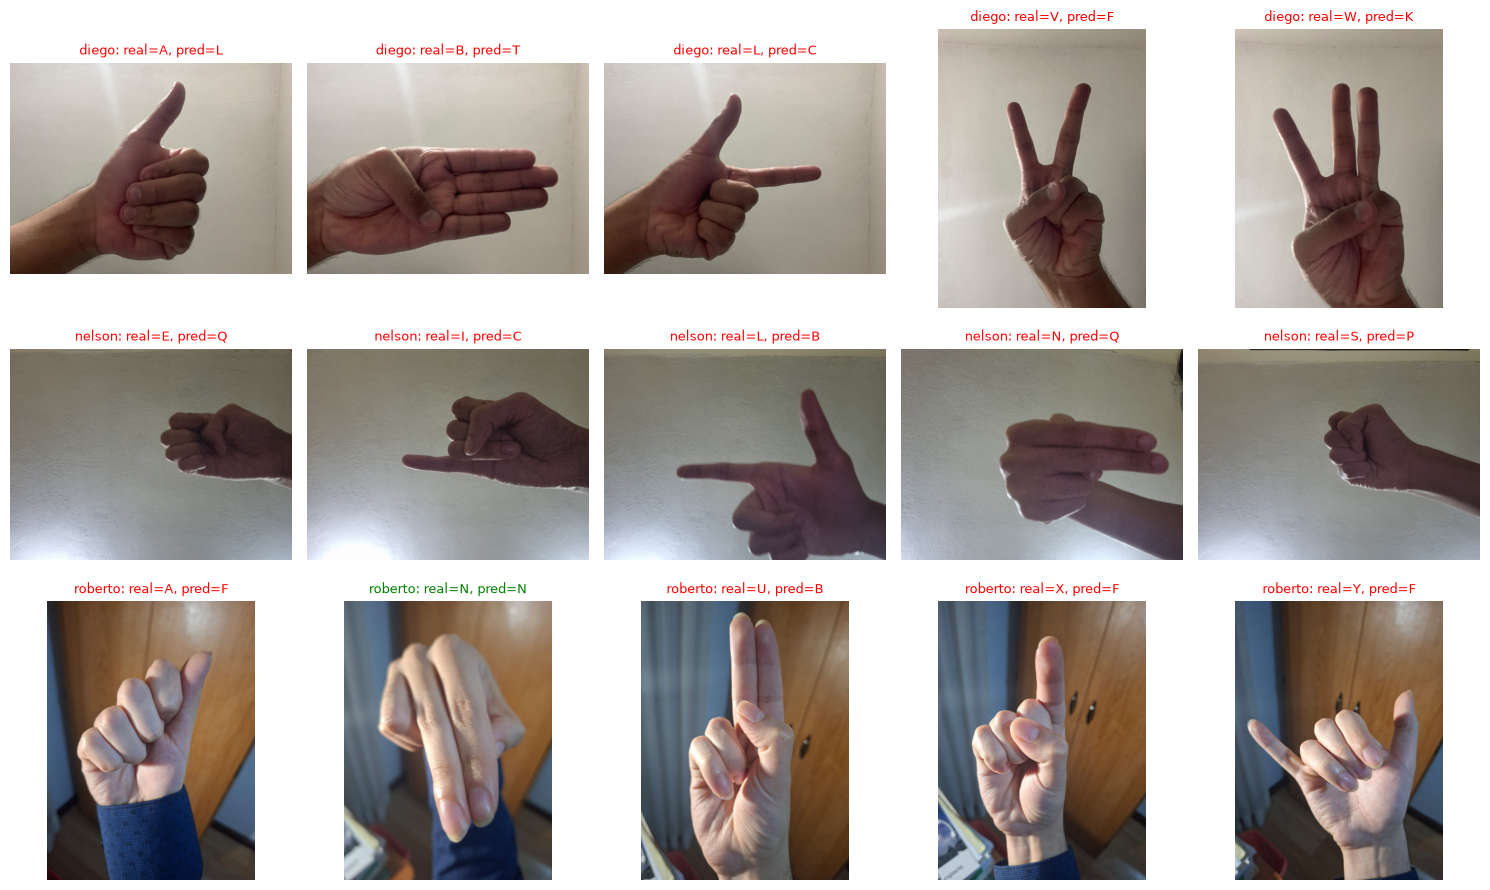

In [7]:
n_ejemplos = min(15, len(fotos_df))
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for ax, (_, fila) in zip(axes.flatten(), fotos_df.head(n_ejemplos).iterrows()):
    img = Image.open(fila["ruta"]).convert("RGB")
    ax.imshow(img)
    color = "green" if fila["correcto"] else "red"
    ax.set_title(
        f"{fila['integrante']}: real={fila['letra_real']}, pred={fila['letra_predicha']}",
        color=color,
        fontsize=9
    )
    ax.axis("off")

for ax in axes.flatten()[n_ejemplos:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Resumen de desempeño

In [8]:
accuracy_global = fotos_df["correcto"].mean()
accuracy_por_integrante = fotos_df.groupby("integrante")["correcto"].mean()

print(f"Accuracy global sobre fotos propias: {accuracy_global*100:.2f}%")
print("\nAccuracy por integrante:")
print(accuracy_por_integrante)


Accuracy global sobre fotos propias: 6.67%

Accuracy por integrante:
integrante
diego      0.0
nelson     0.0
roberto    0.2
Name: correcto, dtype: float64


In [9]:
fotos_df.to_csv(Path("../results") / "fotos_propias.csv", index=False)
print("Guardado en results/fotos_propias.csv")


Guardado en results/fotos_propias.csv


### Discusión (ejercicio 8)

Sobre las 15 fotos propias del equipo, el modelo acertó en **6.67%** de los casos. Este número comparado contra el accuracy de 6.67% obtenido sobre el conjunto de prueba del dataset original en `05_comparacion_final.ipynb` es practicamente identico, a pesar que estas fotos se tomaron con cámaras, fondos e iluminación distintos a los del dataset de Kaggle. 

## Reflexión de accesibilidad y sesgo (ejercicio 9)

**¿Qué limitaciones tiene este dataset para un producto real de accesibilidad como el de SignBridge?**

- **Diversidad de tono de piel y de manos.** El dataset ASL Alphabet de Kaggle se grabó con un número muy reducido de personas bajo las mismas condiciones, por lo que no representa la variedad real de tonos de piel, tamaños de mano ni formas de mano (por edad, por ejemplo) que tendría la base de usuarios de una app educativa. Un modelo entrenado únicamente sobre estas imágenes puede funcionar peor para cualquier usuario cuya piel o mano se aleje de las que aparecen en el dataset — exactamente el tipo de sesgo que un producto de accesibilidad no se puede permitir, porque afectaría de forma desigual a distintos grupos de usuarios.
- **Fondo e iluminación homogéneos.** Todas las fotos del dataset se tomaron en el mismo entorno, con el mismo fondo y la misma iluminación — algo que ya se había notado en el EDA: al restarle a cada clase el promedio de todas las clases, el fondo prácticamente desaparece, lo que confirma que es casi idéntico en las 29 carpetas. Otros equipos que han trabajado con este mismo dataset reportan que un modelo entrenado solo con estas imágenes tiende a fallar frente a fondos distintos a los del dataset original, porque puede terminar apoyándose en pistas del fondo en vez de aprender exclusivamente la forma de la mano. La caída de accuracy que se vio arriba al probar con las fotos propias del equipo (tomadas en entornos distintos) es un ejemplo directo de este problema.
- **Ángulo y encuadre de cámara.** Las imágenes del dataset muestran la mano centrada, a una distancia y ángulo similares en todas las fotos. Un usuario real sosteniendo su celular o laptop frente a la cámara podría hacerlo desde ángulos y distancias muy distintos, que el modelo nunca vio durante el entrenamiento.
- **Calidad de las propias etiquetas.** Se ha reportado que en este dataset en particular algunas señas (por ejemplo, la de la letra T) no corresponden exactamente a la seña real del alfabeto ASL. Esto introduce un sesgo directamente en el ground truth: el modelo puede aprender a reproducir con precisión una seña que en la vida real no es la correcta, lo cual sería especialmente problemático en un producto pensado para enseñar el lenguaje de señas.

**¿Qué haría falta para llevar este prototipo a un caso de uso real como el de SignBridge?**

Antes de llevar el prototipo a producción sería necesario complementar el dataset de entrenamiento con datos que capturen mayor diversidad de personas, tonos de piel, fondos, iluminación y ángulos de cámara, y — más importante todavía — usar ese conjunto complementario como un **conjunto de prueba independiente** (no solo de entrenamiento), para medir de forma explícita cuánto se degrada el desempeño del modelo fuera de las condiciones controladas del dataset de Kaggle. La prueba con las 15+ fotos propias del equipo hecha en este notebook es exactamente un primer paso en esa dirección, pero para un producto real haría falta repetirla con una muestra bastante más grande y demográficamente diversa, e idealmente con participación de usuarios sordos o de la comunidad ASL que puedan validar que las señas capturadas son correctas.